# Start here

Build a trading strategy for Bittensor subnets, test it on real past data, then let your miner run it live. About 30 minutes.

Run the cells in order (Shift + Enter). The first one prepares Google Colab; on a laptop it does nothing.

In [1]:
# On Google Colab, this cell downloads the workshop. On your laptop, it does nothing.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("subnet_trading"):
    if not os.path.exists("subnet-trading-workshop"):
        subprocess.run(["git", "clone", "-q", "https://github.com/42-bittensor-workshop/subnet-trading-workshop.git"], check=True)
    os.chdir("subnet-trading-workshop")
    sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
from subnet_trading import *

pd.set_option("display.float_format", "{:.4f}".format)

## 1. The game

- You start with **1,000 TAO** (virtual).
- Every **15 minutes**, your miner sends a list of **up to 10 subnets with weights**, for example `{64: 0.5, 4: 0.3, 51: 0.2}`.
- After a 5-minute pause, your TAO is placed that way for 10 minutes. Then the round's result comes in, and the next round starts.
- You **gain** when your subnets do better than the average subnet, and **lose** when they do worse. Every trade costs a small **fee**.
- Your account **carries over**: each round plays with the TAO you have.
- Whoever has the most TAO at the end wins.

Only the 50 subnets with the most TAO in their pool count.

## 2. Look at the market

In [3]:
market = load()   # February 2026, one snapshot every 15 minutes
print(f"{len(market.times)} snapshots, from {market.times[0]:%Y-%m-%d} to {market.times[-1]:%Y-%m-%d}")

now = market.times[-1]
biggest = market.universe(now)[:10]
pd.DataFrame({
    "price (TAO)": market.price.loc[now, biggest],
    "TAO in pool": market.tao_in.loc[now, biggest].round(0),
    "change over the last hour (%)": (100 * change(market.price, "1h").loc[now, biggest]).round(3),
})

2680 snapshots, from 2026-02-01 to 2026-03-01


,price (TAO),TAO in pool,change over the last hour (%)
netuid,,,
64,0.1017,232038.0000,0.0050
4,0.0426,105253.0000,0.0980
51,0.0416,96313.0000,-0.0010
8,0.0396,91973.0000,-0.0010
120,0.0858,87090.0000,-0.0940
3,0.0347,78550.0000,0.0000
62,0.0462,59642.0000,0.0320
56,0.0227,58040.0000,-0.0500
44,0.0334,52729.0000,0.0190


Each subnet has a price in TAO that moves all the time. `market.price` holds every price at every snapshot: one row per time, one column per subnet (its number, the *netuid*).

## 3. Your first strategy: pick by hand

Choose a few subnets and weights, then **backtest**: replay a past day with the real rules (pause, fees, everything) and see what would have happened.

In [4]:
my_pick = {64: 0.4, 4: 0.3, 51: 0.3}

day = dict(start="2026-02-20", end="2026-02-21")
result = backtest(my_pick, market, **day)
result.summary()

final value                    987.2000
gain %                          -1.3000
rounds                          47.0000
fees paid                        2.5000
traded per round %               2.1000
rounds without valid weights     0.0000
dtype: float64

Holding the same subnets all day costs a fee only once, at the start. The gain comes from whether those subnets beat the average.

## 4. A signal: let the data choose

A **signal** gives every subnet a number; your miner buys the 10 highest. A simple idea: subnets that rose in the last hour may keep rising.

In [5]:
rising = change(market.price, "1h")     # price change over the last hour, for every subnet and time

table, results = compare({
    "by hand": my_pick,
    "rose in the last hour": rising,
    "random picks": random_strategy(seed=0),
}, market, **day)
table

,final value,gain %,rounds,fees paid,traded per round %,rounds without valid weights
by hand,987.2000,-1.3000,47.0000,2.5000,2.1000,0.0000
rose in the last hour,1130.8000,13.1000,47.0000,116.5000,87.7000,0.0000
random picks,763.5000,-23.7000,47.0000,152.7000,151.9000,0.0000


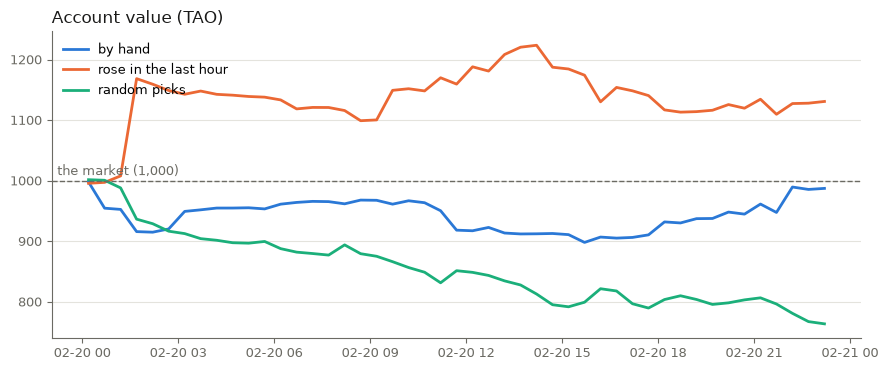

In [6]:
plot_accounts(results);

## 5. Fees

Every time you change your weights, you pay 0.25% of the amount you trade. Selling one subnet to buy another trades twice. `rebalance_cost` tells you the fee in advance, here for an account of 1,000 TAO:

In [7]:
print("start with 2 subnets:      ", rebalance_cost({}, {64: 0.5, 4: 0.5}), "TAO")
print("swap one subnet for another:", rebalance_cost({64: 0.5, 4: 0.5}, {64: 0.5, 8: 0.5}), "TAO")
print("change nothing:             ", rebalance_cost({64: 0.5, 4: 0.5}, {64: 0.5, 4: 0.5}), "TAO")

start with 2 subnets:       2.5 TAO
swap one subnet for another: 2.5 TAO
change nothing:              0.0 TAO


Look at the *fees paid* column in the table above. Random picks change everything every 15 minutes and pay a lot. A good signal must gain more than it pays.

## 6. Skill or luck?

One good day proves little. Test the same strategy on a whole week, day by day, next to random picks.

In [8]:
rows = {}
for d in pd.date_range("2026-02-15", "2026-02-21"):
    window = dict(start=d, end=d + pd.Timedelta(days=1))
    rows[f"{d:%a %d}"] = {
        "rose in the last hour": backtest(rising, market, **window).value,
        "random picks": backtest(random_strategy(seed=d.day), market, **window).value,
    }
pd.DataFrame(rows).T.round(0)

,rose in the last hour,random picks
Sun 15,1113.0000,879.0000
Mon 16,877.0000,1028.0000
Tue 17,1087.0000,669.0000
Wed 18,828.0000,733.0000
Thu 19,931.0000,768.0000
Fri 20,1131.0000,972.0000
Sat 21,880.0000,734.0000


Compare the two columns day by day. Over a single week, luck weighs a lot: even a strategy with a real edge loses on some days, and random picks win now and then. A strategy you can trust beats random picks over many days, not just on one. That is what professional traders look for: an edge that repeats.

## 7. Your turn: try ideas

`docs/IDEAS.md` lists ideas with the line of code for each. Four to start:

In [9]:
ideas = {
    "rose in the last hour": change(market.price, "1h"),
    "TAO flowing into the pool": change(market.tao_in, "1h"),
    "fell in the last 15 minutes": -change(market.price, "15m"),
    "more holders than yesterday": change(market.holders, "1d"),
}
table, results = compare(ideas, market, **day)
table

,final value,gain %,rounds,fees paid,traded per round %,rounds without valid weights
rose in the last hour,1130.8000,13.1000,47.0000,116.5000,87.7000,0.0000
TAO flowing into the pool,1146.1000,14.6000,47.0000,118.2000,88.1000,0.0000
fell in the last 15 minutes,739.2000,-26.1000,47.0000,141.1000,138.3000,0.0000
more holders than yesterday,939.8000,-6.0000,47.0000,4.5000,3.8000,0.0000


Two ideas can be the same idea in disguise. A subnet's price is the TAO in its pool divided by the alpha in its pool, so when TAO flows in, the price rises: the first two ideas pick almost the same subnets.

Change a window (`"1h"` to `"4h"`), combine two signals (`rank(a) + rank(b)`), or write your own. Then test it on several days, as in step 6, before trusting it.

## 8. Your miner

Your miner runs your strategy every 15 minutes and sends the result. This is exactly what it would send right now:

In [10]:
def my_strategy(market):
    return change(market.price, "1h")

next_weights(my_strategy, market)

{22: 0.1,
 4: 0.1,
 35: 0.1,
 18: 0.1,
 62: 0.1,
 75: 0.1,
 6: 0.1,
 11: 0.1,
 19: 0.1,
 44: 0.1}

During the event, you start your miner with `run(my_strategy, get_market, send)`. The organisers give you `get_market` (the live market) and `send` (delivery to the validator). Your strategy can be a signal like this one, your own function, or fixed weights such as `{64: 0.5, 4: 0.5}`.

Before the event, try your strategy live with the practice game. Save it in a file with a `strategy(market)` function, like `strategies/example_strategy.py`, then run in a terminal:

```bash
python scripts/practice.py --strategy strategies/example_strategy.py
```

It plays the real rules on live prices and shows your account on a dashboard. **One last thing:** what worked in the past may not work next. Live, you will find out!